Chi^2 Analysis


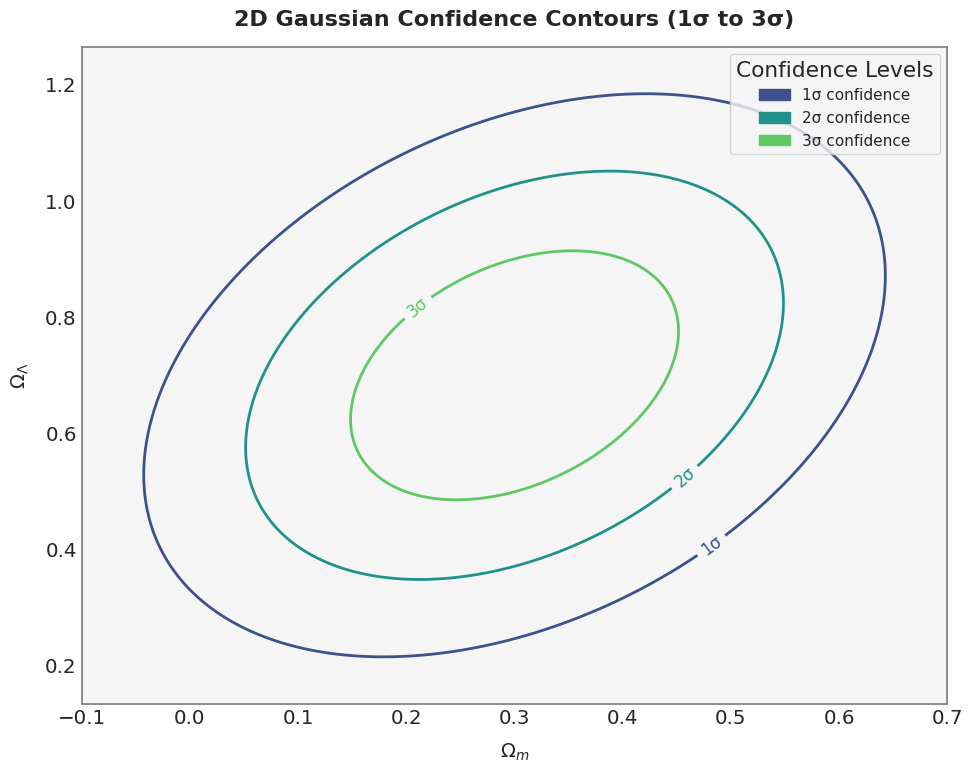

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
import seaborn as sns
from matplotlib.patches import Patch

# Seaborn theme: light background, no grid
sns.set_theme(style='white', font_scale=1.3, rc={
    'axes.facecolor': '#f5f5f5',   # Soft gray background
    'axes.edgecolor': 'gray',
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'axes.grid': False
})

# Gaussian parameters
mean = [0.3, 0.7]
cov = [[0.01, 0.005], [0.005, 0.02]]

# Axis limits for up to 3σ
sigma_x = np.sqrt(cov[0][0])
sigma_y = np.sqrt(cov[1][1])
x_min, x_max = mean[0] - 4*sigma_x, mean[0] + 4*sigma_x
y_min, y_max = mean[1] - 4*sigma_y, mean[1] + 4*sigma_y

# Grid
x = np.linspace(x_min, x_max, 500)
y = np.linspace(y_min, y_max, 500)
X, Y = np.meshgrid(x, y)
pos = np.dstack((X, Y))

# Multivariate normal PDF
rv = multivariate_normal(mean, cov)
Z = rv.pdf(pos)

# Confidence levels (1σ, 2σ, 3σ)
confidence_levels = [0.6827, 0.9545, 0.9973]

def find_sigma_levels(Z, levels):
    Z_flat = Z.ravel()
    Z_sort = np.sort(Z_flat)[::-1]
    cdf = np.cumsum(Z_sort)
    cdf /= cdf[-1]
    return [Z_sort[np.searchsorted(cdf, cl)] for cl in levels]

# Find sorted contour levels
sigma_levels = sorted(find_sigma_levels(Z, confidence_levels))

# Viridis palette (green-blue-purple)
colors = sns.color_palette("viridis", len(sigma_levels))

# Plot
fig, ax = plt.subplots(figsize=(10, 8))
cp = ax.contour(X, Y, Z, levels=sigma_levels, colors=colors, linewidths=2)

# Label contours
sigma_labels = [1, 2, 3]
label_dict = {l: f'{s}σ' for l, s in zip(sigma_levels, sigma_labels)}
ax.clabel(cp, inline=True, fmt=label_dict, fontsize=12)

# Legend
legend_handles = [Patch(color=c, label=f'{s}σ confidence') for c, s in zip(colors, sigma_labels)]
ax.legend(handles=legend_handles, title='Confidence Levels', loc='upper right', fontsize=11)

# Labels and title
ax.set_xlabel(r'$\Omega_m$', fontsize=14, labelpad=10)
ax.set_ylabel(r'$\Omega_\Lambda$', fontsize=14, labelpad=10)
ax.set_title('2D Gaussian Confidence Contours (1σ to 3σ)', fontsize=16, weight='bold', pad=15)

# Limits
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)

# Final layout
plt.tight_layout()
plt.show()
